100%|██████████| 170M/170M [05:46<00:00, 492kB/s]


SGD Epoch 1 Loss: 1.8752 Accuracy: 31.46
SGD Epoch 2 Loss: 1.349 Accuracy: 51.43
SGD Epoch 3 Loss: 1.1306 Accuracy: 59.63
SGD Epoch 4 Loss: 0.9584 Accuracy: 66.32
SGD Epoch 5 Loss: 0.8375 Accuracy: 70.94
SGD Epoch 6 Loss: 0.7353 Accuracy: 74.2
SGD Epoch 7 Loss: 0.6525 Accuracy: 77.13
SGD Epoch 8 Loss: 0.5687 Accuracy: 80.27
SGD Epoch 9 Loss: 0.4951 Accuracy: 82.66
SGD Epoch 10 Loss: 0.4169 Accuracy: 85.32
Adam Epoch 1 Loss: 1.4569 Accuracy: 47.07
Adam Epoch 2 Loss: 1.0562 Accuracy: 62.18
Adam Epoch 3 Loss: 0.8671 Accuracy: 69.54
Adam Epoch 4 Loss: 0.7508 Accuracy: 73.57
Adam Epoch 5 Loss: 0.646 Accuracy: 77.32
Adam Epoch 6 Loss: 0.5563 Accuracy: 80.65
Adam Epoch 7 Loss: 0.4811 Accuracy: 83.3
Adam Epoch 8 Loss: 0.4008 Accuracy: 85.86
Adam Epoch 9 Loss: 0.3373 Accuracy: 88.15
Adam Epoch 10 Loss: 0.2683 Accuracy: 90.63
SGD Test Accuracy: 73.84 %
Adam Test Accuracy: 75.18 %


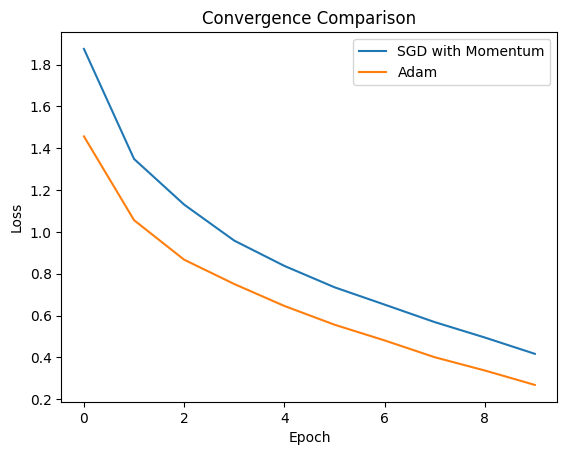

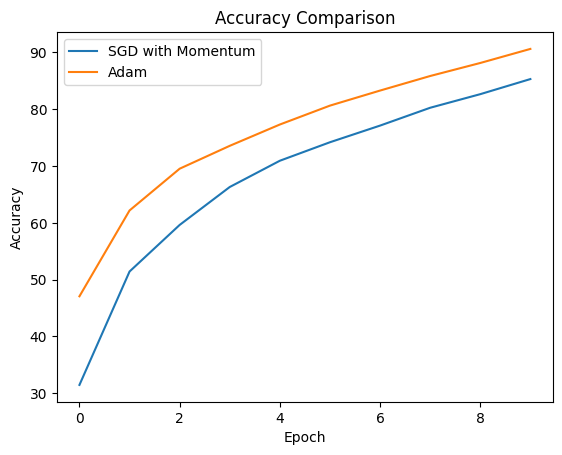

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=128,
    shuffle=True
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=128,
    shuffle=False
)

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x

def train_model(name):
    model = CNN().to(device)
    criterion = nn.CrossEntropyLoss()

    if name == "SGD":
        optimizer = optim.SGD(
            model.parameters(),
            lr=0.01,
            momentum=0.9
    )
    else:
        optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    losses = []
    accuracies = []

    for epoch in range(10):
        model.train()
        running_loss = 0
        correct = 0
        total = 0

        for images, labels in trainloader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        loss_value = running_loss / len(trainloader)
        accuracy = 100 * correct / total

        losses.append(loss_value)
        accuracies.append(accuracy)

        print(name, "Epoch", epoch + 1,
            "Loss:", round(loss_value, 4),
            "Accuracy:", round(accuracy, 2))

    return model, losses, accuracies

def test_model(model):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in testloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return 100 * correct / total

sgd_model, sgd_loss, sgd_acc = train_model("SGD")

adam_model, adam_loss, adam_acc = train_model("Adam")

sgd_test = test_model(sgd_model)
adam_test = test_model(adam_model)

print("SGD Test Accuracy:", round(sgd_test, 2), "%")
print("Adam Test Accuracy:", round(adam_test, 2), "%")

plt.plot(sgd_loss, label="SGD with Momentum")
plt.plot(adam_loss, label="Adam")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Convergence Comparison")
plt.legend()
plt.show()

plt.plot(sgd_acc, label="SGD with Momentum")
plt.plot(adam_acc, label="Adam")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison")
plt.legend()
plt.show()